# Q1.1 Load and clean

In [1]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")

df = pd.read_json("research_abstracts.json")
print(df.shape)
print(df["Label"].value_counts())

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", " ", text)      
    text = re.sub(r"<[^>]+>", " ", text)       
    text = re.sub(r"[^a-z\s]", " ", text)      
    words = text.split()

    clean_words = []
    for word in words:
        if word not in stop_words and len(word) > 2:
            clean_words.append(lemmatizer.lemmatize(word))
    return " ".join(clean_words)

df["clean"] = df["Abstract"].apply(clean_text)

df = df[df["clean"].str.len() > 0]
df = df.drop_duplicates(subset="clean")
df = df.reset_index(drop=True)
print(df.shape)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dikel\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dikel\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


(1138, 3)
Label
classical    900
ai           238
Name: count, dtype: int64
(1118, 4)


# Q1.2 Pick the columns

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
import numpy as np

print("Missing DOIs:", df["DOI"].isna().sum())
print("Unique DOIs:", df["DOI"].nunique(), "out of", len(df))

df["target"] = df["Label"].map({"ai": 0, "classical": 1})

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.85)
X = tfidf.fit_transform(df["clean"])
y = df["target"]

scores, p_values = chi2(X, y)
terms = tfidf.get_feature_names_out()
best = np.argsort(scores)[-15:][::-1]
for i in best:
    print(terms[i], round(scores[i], 1))

Missing DOIs: 2
Unique DOIs: 1116 out of 1118
machine 21.2
network 20.9
neural 20.5
neural network 19.9
machine learning 19.0
learning 18.8
algorithm 15.8
lstm 12.4
svr 12.0
ann 11.2
gold 11.0
quantile 10.6
method 9.7
artificial 9.2
forest 9.1


# Q1.3 Baseline model

Train macro F1: 0.92
Test macro F1: 0.816
              precision    recall  f1-score   support

          ai       0.93      0.55      0.69        47
   classical       0.89      0.99      0.94       177

    accuracy                           0.90       224
   macro avg       0.91      0.77      0.82       224
weighted avg       0.90      0.90      0.89       224

5-fold CV: 0.83


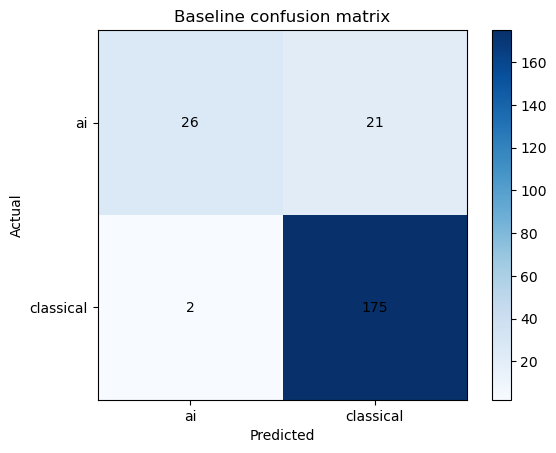

In [4]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean"], y, test_size=0.2, stratify=y, random_state=42)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.85)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

baseline = MultinomialNB(alpha=0.3)
baseline.fit(X_train, y_train)

train_pred = baseline.predict(X_train)
test_pred = baseline.predict(X_test)

print("Train macro F1:", round(f1_score(y_train, train_pred, average="macro"), 3))
print("Test macro F1:", round(f1_score(y_test, test_pred, average="macro"), 3))
print(classification_report(y_test, test_pred, target_names=["ai", "classical"]))

cv_scores = cross_val_score(baseline, X_train, y_train, cv=5, scoring="f1_macro")
print("5-fold CV:", round(cv_scores.mean(), 3))

cm = confusion_matrix(y_test, test_pred)
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["ai", "classical"])
plt.yticks([0, 1], ["ai", "classical"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline confusion matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i][j], ha="center", va="center")
plt.show()

## 2.1 training at least four machine learning models

                 Model  Accuracy  Macro F1
2           Linear SVM     0.920     0.873
3        Random Forest     0.915     0.848
1  Logistic Regression     0.893     0.841
0          Naive Bayes     0.897     0.816
4        Decision Tree     0.830     0.765


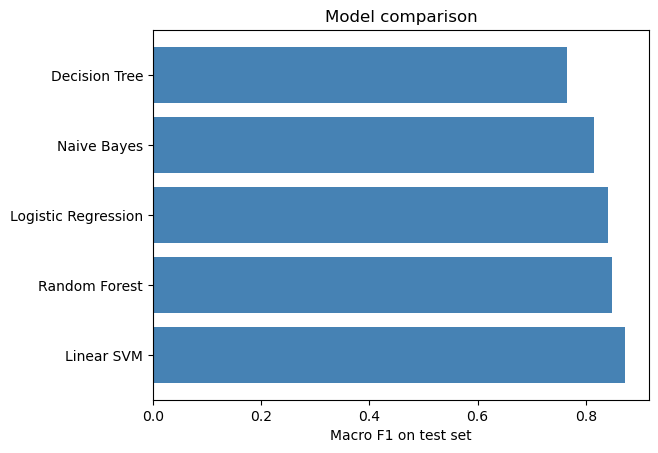

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": round((pred == y_test).mean(), 3),
        "Macro F1": round(f1_score(y_test, pred, average="macro"), 3),
    })

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
print(results_df)

plt.barh(results_df["Model"], results_df["Macro F1"], color="steelblue")
plt.xlabel("Macro F1 on test set")
plt.title("Model comparison")
plt.show()

## 2.2 additional predictive performance enhancement 

Best settings: {'C': 5, 'class_weight': 'balanced'}
F1 before tuning: 0.644
F1 after tuning: 0.85


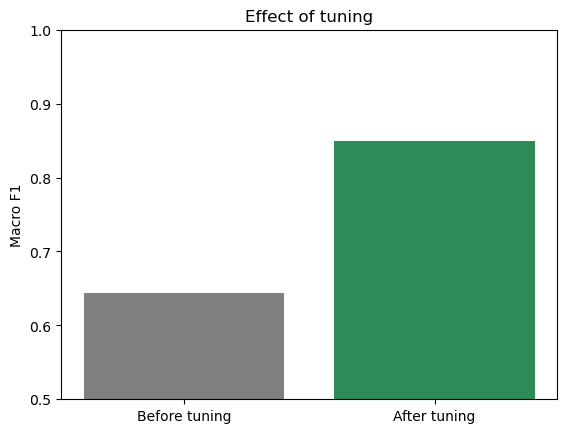

In [6]:
from sklearn.model_selection import GridSearchCV

params = {
    "C": [0.1, 1, 5, 10, 20],
    "class_weight": ["balanced", None],
}

grid = GridSearchCV(LogisticRegression(max_iter=1000), params,
                    cv=5, scoring="f1_macro")
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)

before = LogisticRegression(max_iter=1000)
before.fit(X_train, y_train)
f1_before = f1_score(y_test, before.predict(X_test), average="macro")

best_model = grid.best_estimator_
f1_after = f1_score(y_test, best_model.predict(X_test), average="macro")

print("F1 before tuning:", round(f1_before, 3))
print("F1 after tuning:", round(f1_after, 3))

plt.bar(["Before tuning", "After tuning"], [f1_before, f1_after], color=["gray", "seagreen"])
plt.ylabel("Macro F1")
plt.ylim(0.5, 1)
plt.title("Effect of tuning")
plt.show()

## 2.3 Web interface

In [7]:
import joblib
joblib.dump(best_model, "model.joblib")
joblib.dump(tfidf, "tfidf.joblib")

['tfidf.joblib']

In [10]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

title = widgets.HTML("<h1>Researchly Research Abstract Classifier</h1>"
                     "<p>This app classifies research abstracts as either AI-related or classical research.</p>")
box = widgets.Textarea(placeholder="Enter research abstract", layout=widgets.Layout(width="700px", height="180px"))
button = widgets.Button(description="Classify Abstract")
output = widgets.Output()

def classify(b):
    with output:
        clear_output()
        if box.value.strip() == "":
            display(HTML("<p style='color:orange'>Please enter an abstract first.</p>"))
            return
        cleaned = clean_text(box.value)
        features = tfidf.transform([cleaned])
        prediction = model.predict(features)[0]

        if prediction == 0:
            label = "artificial intelligence"
        else:
            label = "classical research"

        display(HTML("<h2>Prediction</h2>"
                     "<div style='background:#e3f5e8; color:#1a7a3a; padding:12px; width:700px'>"
                     "The abstract is classified as: " + label + "</div>"))

button.on_click(classify)
display(title, box, button, output)

HTML(value='<h1>Researchly Research Abstract Classifier</h1><p>This app classifies research abstracts as eithe…

Textarea(value='', layout=Layout(height='180px', width='700px'), placeholder='Enter research abstract')

Button(description='Classify Abstract', style=ButtonStyle())

Output()